# NN_L3_double_descent

**Double descent on California housing: training and test MSE of a two-layer network with p random, frozen ReLU features and a minimum-norm output layer, n = 400 training block groups, median of 10 draws.**

Neural Networks and Deep Learning (NN), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L3/NN_L3_double_descent/NN_L3_double_descent.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 3 of *Neural Networks and Deep Learning*: the chart `double_descent` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

width of the test-error peak = 400   [dd.peak_p]
best test MSE below the threshold = 0.781   [dd.best_under_mse]
test MSE at p = 8000 = 0.932   [dd.big_mse]


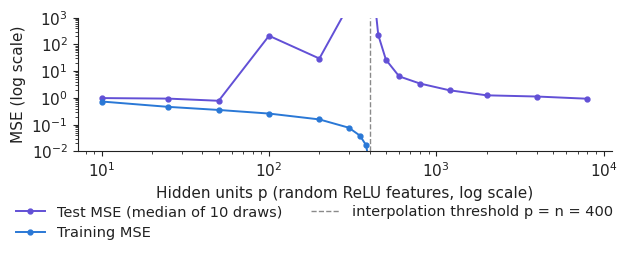

In [3]:
SEED = 20261108

ca = pd.read_csv(DATA + 'california_housing.csv'); feat = [c for c in ca.columns if c != 'MedHouseVal_100k_usd']
Xc = ca[feat].values.astype(np.float64); yc = ca['MedHouseVal_100k_usd'].values.astype(np.float64)
NDD = 400; P = [10, 25, 50, 100, 200, 300, 350, 380, 400, 420, 450, 500, 600, 800, 1200, 2000, 4000, 8000]
out = {p: [] for p in P}
for s in range(10):
    rng = np.random.default_rng(SEED + s); idx = rng.permutation(len(Xc)); tr, te = idx[:NDD], idx[NDD:NDD + 5000]
    mu, sd = Xc[tr].mean(0), Xc[tr].std(0); A, B = (Xc[tr] - mu) / sd, (Xc[te] - mu) / sd
    Wr = rng.normal(0, 1 / np.sqrt(A.shape[1]), (A.shape[1], max(P))); br = rng.normal(0, 1, max(P))
    for p in P:
        Fa, Fb = np.maximum(A @ Wr[:, :p] + br[:p], 0), np.maximum(B @ Wr[:, :p] + br[:p], 0); yt = yc[tr] - yc[tr].mean()
        beta = np.linalg.lstsq(Fa, yt, rcond=None)[0] if p <= NDD else Fa.T @ np.linalg.lstsq(Fa @ Fa.T, yt, rcond=None)[0]
        out[p].append([np.mean((Fa @ beta + yc[tr].mean() - yc[tr]) ** 2), np.mean((Fb @ beta + yc[tr].mean() - yc[te]) ** 2)])
trm = np.array([np.median([x[0] for x in out[p]]) for p in P]); tem = np.array([np.median([x[1] for x in out[p]]) for p in P])
show('dd.peak_p', 'width of the test-error peak', int(P[int(np.argmax(tem))])); show('dd.best_under_mse', 'best test MSE below the threshold', round(float(min(tem[[i for i, p in enumerate(P) if p < NDD]])), 3))
show('dd.big_mse', 'test MSE at p = 8000', round(float(tem[-1]), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.plot(P, tem, 'o-', color=PAL['test'], ms=3.5, label='Test MSE (median of 10 draws)'); ax.plot(P, trm, 'o-', color=PAL['train'], ms=3.5, label='Training MSE')
ax.axvline(NDD, color='#8a8a8a', ls='--', lw=1, label='interpolation threshold p = n = 400'); ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(0.01, 1e3)
ax.set_xlabel('Hidden units p (random ReLU features, log scale)'); ax.set_ylabel('MSE (log scale)')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('double_descent.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()